# External data: Events
## Outdoor events data

The CSV files used in this notebook came from: https://data.cityofchicago.org/Events/Chicago-Park-District-Outdoor-Event-Permits/pk66-w54g/data_preview 

Only records from 2022 up to 2025 were download from Chicago Data Portal.

In [51]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

outdoor = pd.read_csv("data/chicago_outdoor_events.csv", low_memory=False)
print("Total of records:", len(outdoor))
display(outdoor.head())

Total of records: 36447


,Requestor,Organization,Park Number,Park/Facility Name,Reservation Start Date,Reservation End Date,Event Type,Event Description,Permit Status
0,Rebecca Yannopoulos Bladder Cancer Adv. Network,--,34,Northerly Island Visitor Center,01/01/2022,01/01/2022,Venue Rental - Philanthropic,BCAN Walk to End Bladder Cancer,Tentative
1,Elizabeth Rieveley,--,8480,Garfield Conservatory Community Room,01/01/2022,01/01/2022,Venue Rental - Social,Harper's 1st Birthday,Tentative
2,Tanya Larson-Topp,--,8480,Garfield Conservatory Jensen Room,01/01/2022,01/01/2022,Venue Rental - Social,Midwest Staff Retreat,Tentative
3,Maris Rosenfeld,--,8480,Garfield Conservatory Community Room,01/01/2022,01/01/2022,Venue Rental - Social,Young Families Celebrate Passover,Tentative
4,Fleet Feet Chicago,--,100,Lincoln Route on Lakefront Trail,01/01/2022,01/01/2022,Permit - Athletic T Cluster 3,CES Training Aid Station - Montrose,Approved


Columns names are changed to fit the other datasets used for the project, records without start and end dates, park data and requestor were removed and dates were converted to time format.

In [52]:
#Rename relevant columns
column_rename = {
    "Requestor": "requestor",
    "Organization": "organization",
    "Park Number": "park_number",
    "Park/Facility Name": "park_name",
    "Reservation Start Date": "start_date",
    "Reservation End Date": "end_date",
    "Event Type": "event_type",
    "Event Description": "event_description",
    "Permit Status": "permit_status"
}

outdoor = outdoor[list(column_rename.keys())].rename(columns=column_rename).copy()

#Remove records without dates or parks
outdoor = outdoor.dropna(subset=["start_date", "end_date", "park_number", "park_name", "requestor"]).copy()

#Convert dates into date format
date_columns = ["start_date", "end_date"]

for col in date_columns:
    outdoor[col] = pd.to_datetime(outdoor[col], errors="coerce")

print("Total of records:", len(outdoor))
display(outdoor.head())

Total of records: 36447


,requestor,organization,park_number,park_name,start_date,end_date,event_type,event_description,permit_status
0,Rebecca Yannopoulos Bladder Cancer Adv. Network,--,34,Northerly Island Visitor Center,2022-01-01,2022-01-01,Venue Rental - Philanthropic,BCAN Walk to End Bladder Cancer,Tentative
1,Elizabeth Rieveley,--,8480,Garfield Conservatory Community Room,2022-01-01,2022-01-01,Venue Rental - Social,Harper's 1st Birthday,Tentative
2,Tanya Larson-Topp,--,8480,Garfield Conservatory Jensen Room,2022-01-01,2022-01-01,Venue Rental - Social,Midwest Staff Retreat,Tentative
3,Maris Rosenfeld,--,8480,Garfield Conservatory Community Room,2022-01-01,2022-01-01,Venue Rental - Social,Young Families Celebrate Passover,Tentative
4,Fleet Feet Chicago,--,100,Lincoln Route on Lakefront Trail,2022-01-01,2022-01-01,Permit - Athletic T Cluster 3,CES Training Aid Station - Montrose,Approved


For this dataset, several type of duplicates were inspected:
- Exact same records.
- Different records that might refer to the same event.

In [30]:
#Inspect exact same rows
print("Total records:", len(outdoor))
print("Exact duplicate rows:", outdoor.duplicated().sum())

duplicates = outdoor[outdoor.duplicated(keep=False)].sort_values(by=outdoor.columns.tolist())
display(duplicates.head())

#Remove duplicated rows
outdoor = outdoor.drop_duplicates().copy()
print("Total records after removing duplicated rows:", len(outdoor))

Total records: 36447
Exact duplicate rows: 746


,requestor,organization,park_number,park_name,start_date,end_date,event_type,event_description,permit_status
23183,Adam Warshawsky,--,8480,Lincoln Conservatory All Show Rooms,2024-09-07,2024-09-07,Venue Rental - Wedding,Adam & Camilla's Ceremony,Approved
23186,Adam Warshawsky,--,8480,Lincoln Conservatory All Show Rooms,2024-09-07,2024-09-07,Venue Rental - Wedding,Adam & Camilla's Ceremony,Approved
32529,Aiesha Arboleda,--,1303,Maggie Daley Tennis Court Peanut Pk 03,2025-08-08,2025-08-08,Administrative Reservation - Internal Hold PARKS,Aiesha Arboleda,Approved
32533,Aiesha Arboleda,--,1303,Maggie Daley Tennis Court Peanut Pk 03,2025-08-08,2025-08-08,Administrative Reservation - Internal Hold PARKS,Aiesha Arboleda,Approved
32530,Aiesha Arboleda,--,1303,Maggie Daley Tennis Court Peanut Pk 04,2025-08-08,2025-08-08,Administrative Reservation - Internal Hold PARKS,Aiesha Arboleda,Approved


Total records after removing duplicated rows: 35701


In [37]:
#Determine potential same event related records
duplicate_events = outdoor[outdoor.duplicated(subset=["event_description", "start_date", "end_date","park_number"], 
                                              keep=False)].sort_values(["event_description", "start_date", "park_number"])
display(duplicate_events.head())

,requestor,organization,park_number,park_name,start_date,end_date,event_type,event_description,permit_status
9660,Adrians Cleveland,--,219,Humboldt Lawn South of Little Cubs Field,2023-06-03,2023-06-03,Permit - Event 3 Cluster 2,0211 Community Play Cup (Non-exclusive Use),Approved
9661,Adrians Cleveland,--,219,Humboldt Lawn NW of Fieldhouse,2023-06-03,2023-06-03,Permit - Event 3 Cluster 2,0211 Community Play Cup (Non-exclusive Use),Approved
9662,Adrians Cleveland,--,219,Humboldt Lawn North of Little Cubs Field,2023-06-03,2023-06-03,Permit - Event 3 Cluster 2,0211 Community Play Cup (Non-exclusive Use),Approved
9663,Adrians Cleveland,--,219,Humboldt Lawn North - Whipple,2023-06-03,2023-06-03,Permit - Event 3 Cluster 2,0211 Community Play Cup (Non-exclusive Use),Approved
9665,Adrians Cleveland,--,219,Humboldt Lawn West of Beach,2023-06-03,2023-06-03,Permit - Event 3 Cluster 2,0211 Community Play Cup (Non-exclusive Use),Approved


In [40]:
#Records per event combination
event_groups = (outdoor.groupby(["event_description", "start_date", "end_date", "park_number"], dropna=False)
    .agg(permit_count=("requestor", "size"),
        locations=("park_name", "nunique"),
        requestors=("requestor", "nunique"),
        statuses=("permit_status", "nunique")).reset_index())

event_groups = event_groups[event_groups["permit_count"] > 1].sort_values("permit_count", ascending=False)

display(event_groups.head(10))

,event_description,start_date,end_date,park_number,permit_count,locations,requestors,statuses
17514,Lollapalooza 2025,2025-07-31,2025-07-31,24,28,28,1,1
17516,Lollapalooza 2025,2025-08-02,2025-08-02,24,28,28,1,1
17515,Lollapalooza 2025,2025-08-01,2025-08-01,24,28,28,1,1
17513,Lollapalooza 2025,2025-07-30,2025-07-30,24,28,28,1,1
17512,Lollapalooza 2025,2025-07-29,2025-07-29,24,28,28,1,1
17486,Lollapalooza 2024,2024-07-30,2024-07-30,24,28,28,1,1
17511,Lollapalooza 2025,2025-07-28,2025-07-28,24,28,28,1,1
17496,Lollapalooza 2024,2024-08-09,2024-08-09,24,28,28,1,1
17494,Lollapalooza 2024,2024-08-07,2024-08-07,24,28,28,1,1
17495,Lollapalooza 2024,2024-08-08,2024-08-08,24,28,28,1,1


Due to multiple records sharing the same requestor and park number but different locations, it is likely that this records refer to the same event but requesting different locations inside the same park. These records will be grouped together as potential same events.

In [46]:
#Clean data to create events
outdoor_clean = outdoor.copy()

event_columns = ["event_description", "start_date", "end_date", "requestor", "organization"]

outdoor_clean["event_id"] = (outdoor_clean.groupby(event_columns, dropna=False).ngroup())

#Aggregate records into events
outdoor_events = (outdoor_clean.groupby("event_id")
    .agg(event_description=("event_description", "first"),
        start_date=("start_date", "min"),
        end_date=("end_date", "max"),
        requestor=("requestor", "first"),
        organization=("organization", "first"),
        park_number=("park_number", "first"),
        number_of_permits=("event_id", "size"),
        number_of_locations=("park_name", "nunique"),
        locations=("park_name", lambda x: list(x.dropna().unique())),
        event_types=("event_type", lambda x: list(x.dropna().unique())),
        permit_statuses=("permit_status", lambda x: list(x.dropna().unique()))
    ).reset_index())

print("Original permit records:", len(outdoor))
print("Candidate events:", len(outdoor_events))
display(outdoor_events.head())

Original permit records: 35701
Candidate events: 27128


,event_id,event_description,start_date,end_date,requestor,organization,park_number,number_of_permits,number_of_locations,locations,event_types,permit_statuses
0,0,"""HIV and the Journey Toward Zero""",2023-05-25,2023-05-25,Alexis Jaworski,--,218,1,1,[Douglass Terrace],[Permit - Media: Filming Level 1],[Approved]
1,1,"""Soil"" book club discussion",2023-08-19,2023-08-19,Cynthia Okechukwu,--,8480,1,1,[Garfield Conservatory Community Room],[Venue Rental - Social],[Approved]
2,2,#286704 Learn to Swim (Special Rec) at Owens,2022-01-07,2022-01-07,David Bustos Owens Park,--,255,1,1,[Carver Natatorium],[Administrative Reservation - Internal Hold PA...,[Approved]
3,3,#286704 Learn to Swim (Special Rec) at Owens,2022-01-14,2022-01-14,David Bustos Owens Park,--,255,1,1,[Carver Natatorium],[Administrative Reservation - Internal Hold PA...,[Approved]
4,4,#286704 Learn to Swim (Special Rec) at Owens,2022-01-21,2022-01-21,David Bustos Owens Park,--,255,1,1,[Carver Natatorium],[Administrative Reservation - Internal Hold PA...,[Approved]


With a list of candidates events, the data should be inspected to seen if filtering needs to be done to retain only relevant data to the research.

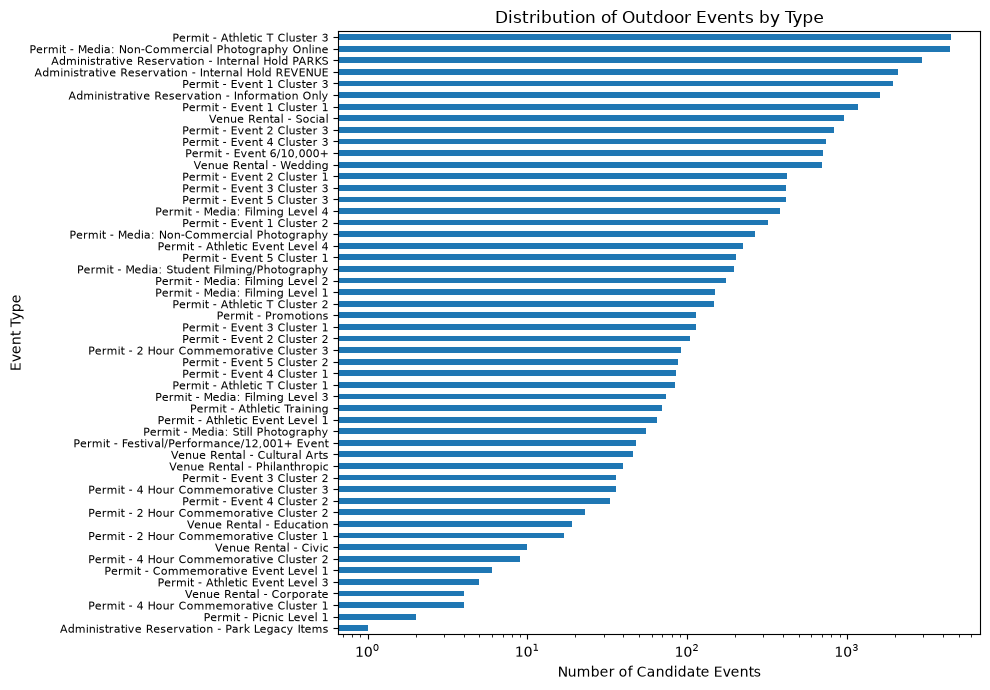

In [56]:
#Events distribution by type
event_type_counts = (outdoor_events["event_types"].explode().value_counts().sort_values())
event_type_counts.plot(kind="barh", figsize=(10, 7))

plt.title("Distribution of Outdoor Events by Type")
plt.xlabel("Number of Candidate Events")
plt.ylabel("Event Type")
plt.xscale("log")
plt.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

For easier manipulation, event types agre grouped together into broader categories.

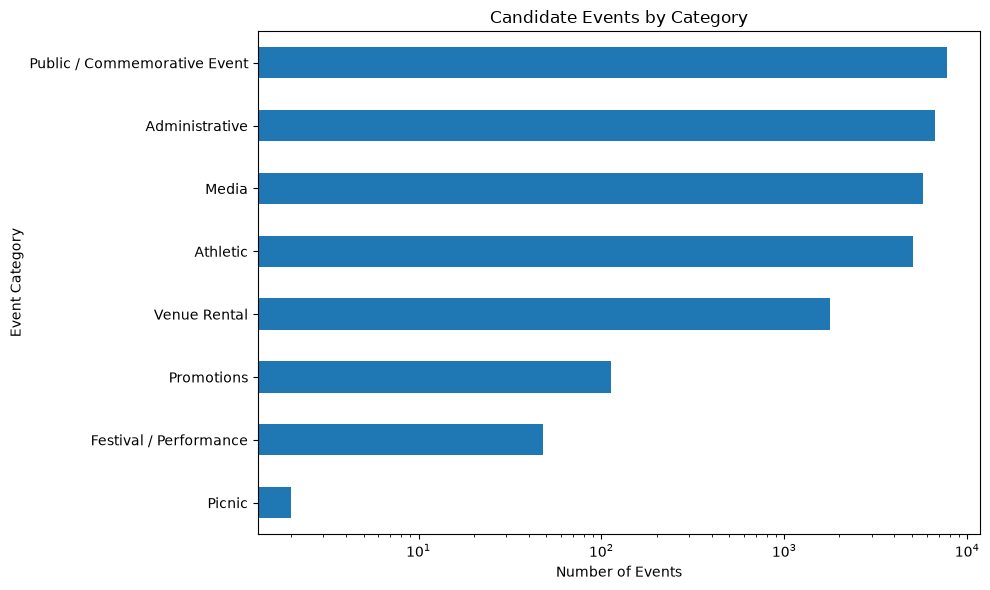

In [72]:
#Creating broader categories
def categorize_event(event_type):

    if pd.isna(event_type):
        return "Unknown"

    if "Administrative Reservation" in event_type:
        return "Administrative"

    elif "Media" in event_type:
        return "Media"

    elif "Athletic" in event_type:
        return "Athletic"

    elif "Festival" in event_type:
        return "Festival / Performance"

    elif "Event" in event_type or "Commemorative" in event_type:
        return "Public / Commemorative Event"

    elif "Venue Rental" in event_type:
        return "Venue Rental"

    elif "Picnic" in event_type:
        return "Picnic"

    elif "Promotions" in event_type:
        return "Promotions"

    else:
        return "Other"

outdoor_clean["event_category"] = (outdoor_clean["event_type"].apply(categorize_event))
outdoor_events["event_categories"] = (outdoor_events["event_types"].apply(
        lambda types: list(set(categorize_event(t) for t in types))))

#Plotting broard categories
category_counts = (outdoor_events["event_categories"].explode().value_counts().sort_values())
category_counts.plot(kind="barh",figsize=(10, 6))

plt.title("Candidate Events by Category")
plt.xlabel("Number of Events")
plt.ylabel("Event Category")
plt.xscale("log")
plt.tight_layout()
plt.show()

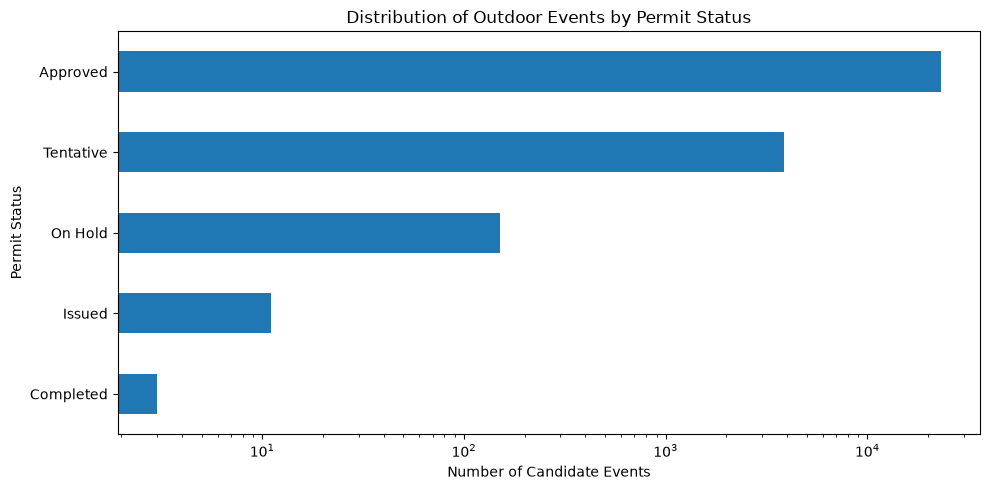

In [59]:
#Event distribution by status
status_counts = (outdoor_events["permit_statuses"].explode().value_counts().sort_values())

status_counts.plot(kind="barh", figsize=(10, 5))

plt.title("Distribution of Outdoor Events by Permit Status")
plt.xlabel("Number of Candidate Events")
plt.ylabel("Permit Status")
plt.xscale("log")
plt.tight_layout()
plt.show()

For the final dataset to use, it would be retain only those permits marked as approved as they are events more likely to have occured. Regarding event type, the ones with the highest potential to have affected bike-sharing activity are public events, athletic events and festivals while venue rental could include some large getherings. The rest (administrative, media, promotions, picnic) are less likely to have caused an impact and will be filtered out of the dataset, even if some account for a substantial number of records.

In [76]:
#Filtering the data
selected_statuses = ["Approved"]
selected_categories = ["Public / Commemorative Event", "Festival / Performance", "Athletic", "Venue Rental"]

outdoor_events_main = outdoor_events[outdoor_events["event_categories"].apply(
        lambda categories: any(category in selected_categories for category in categories))].copy()
outdoor_events_main = outdoor_events_main[outdoor_events_main["permit_statuses"].apply(
        lambda statuses: any(status in selected_statuses for status in statuses))].copy()

print("Original candidate events:", len(outdoor_events))
print("Candidate events after filtering:", len(outdoor_events_main))

Original candidate events: 27128
Candidate events after filtering: 14177
